<a href="https://colab.research.google.com/github/Sasidhar015/Data-engineering-training-2026/blob/main/Capstone%20Projects/Smart%20Home%20Energy%20Usage%20Tracker/Week%202/data_cleaning.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
from google.colab import files
uploaded = files.upload()

Saving rooms.csv to rooms.csv


In [4]:
from google.colab import files
uploaded = files.upload()

Saving energy_logs_raw.csv to energy_logs_raw.csv


In [5]:
import pandas as pd
import numpy as np

In [6]:
df = pd.read_csv("energy_logs_raw.csv")
print("Raw rows:", len(df))
df.head(10)

Raw rows: 10110


,log_id,device_id,room_id,timestamp,energy_kwh,power_watts
0,1,D01,R01,2026-09-01 00:00:00,1.0275,1027.5
1,2,D02,R01,2026-09-01 00:00:00,0.0024,2.4
2,3,D03,R01,2026-09-01 00:00:00,0.0014,1.4
3,4,D04,R02,2026-09-01 00:00:00,0.9964,996.4
4,5,D05,R02,2026-09-01 00:00:00,0.0004,0.4
5,6,D06,R03,2026-09-01 00:00:00,0.0713,71.3
6,7,D07,R03,2026-09-01 00:00:00,0.0003,0.3
7,8,D08,R04,2026-09-01 00:00:00,0.0710,71.0
8,9,D09,R04,2026-09-01 00:00:00,0.0200,20.0
9,10,D10,R04,2026-09-01 00:00:00,0.0005,0.5


In [7]:
print(df.dtypes)
print()
print("Missing values per column:")
print(df.isna().sum())
print("Negative energy:", (pd.to_numeric(df["energy_kwh"], errors="coerce") < 0).sum())
print("Duplicate rows:", df.duplicated(subset=["device_id", "timestamp"]).sum())

log_id           int64
device_id       object
room_id         object
timestamp       object
energy_kwh     float64
power_watts    float64
dtype: object

Missing values per column:
log_id           0
device_id        0
room_id          0
timestamp        0
energy_kwh     147
power_watts      0
dtype: int64
Negative energy: 31
Duplicate rows: 46


In [8]:
df["timestamp"]   = pd.to_datetime(df["timestamp"], errors="coerce")
df["energy_kwh"]  = pd.to_numeric(df["energy_kwh"], errors="coerce")
df["power_watts"] = pd.to_numeric(df["power_watts"], errors="coerce")
print(df.dtypes)

log_id                  int64
device_id              object
room_id                object
timestamp      datetime64[ns]
energy_kwh            float64
power_watts           float64
dtype: object


In [9]:
before = len(df)
df = df.dropna(subset=["timestamp", "energy_kwh", "device_id"])
print("Dropped", before - len(df), "rows with missing/malformed values")

Dropped 177 rows with missing/malformed values


In [10]:
before = len(df)
df = df[(df["energy_kwh"] >= 0) & (df["energy_kwh"] <= 5)]
print("Dropped", before - len(df), "negative/spike rows")

Dropped 51 negative/spike rows


In [11]:
before = len(df)
df = df.drop_duplicates(subset=["device_id", "timestamp"], keep="first")
print("Dropped", before - len(df), "duplicate rows")

Dropped 29 duplicate rows


In [12]:
df = df.sort_values(["timestamp", "device_id"]).reset_index(drop=True)
print("Clean rows:", len(df))
df.to_csv("energy_logs_clean.csv", index=False)
df.head()

Clean rows: 9853


,log_id,device_id,room_id,timestamp,energy_kwh,power_watts
0,1,D01,R01,2026-09-01,1.0275,1027.5
1,2,D02,R01,2026-09-01,0.0024,2.4
2,3,D03,R01,2026-09-01,0.0014,1.4
3,4,D04,R02,2026-09-01,0.9964,996.4
4,5,D05,R02,2026-09-01,0.0004,0.4


In [13]:
rows = []
for dev, grp in df.groupby("device_id"):
    vals = grp["energy_kwh"].to_numpy()
    rows.append({
        "device_id": dev,
        "total_kwh": round(float(np.sum(vals)), 3),
        "avg_kwh_per_reading": round(float(np.mean(vals)), 4),
        "max_kwh": round(float(np.max(vals)), 4),
    })
device_summary = pd.DataFrame(rows).sort_values("total_kwh", ascending=False)
device_summary

,device_id,total_kwh,avg_kwh_per_reading,max_kwh
0,D01,271.239,0.3831,1.3194
3,D04,232.675,0.3310,1.2098
10,D11,102.453,0.1459,2.1656
7,D08,39.497,0.0560,0.0750
8,D09,28.149,0.0398,1.0560
13,D14,16.652,0.0236,0.5499
5,D06,16.628,0.0235,0.0769
1,D02,16.599,0.0235,0.1314
11,D12,14.561,0.0208,0.0714
2,D03,13.816,0.0198,0.0770


In [14]:
rooms = pd.read_csv("rooms.csv")
room_summary = (df.groupby("room_id")["energy_kwh"]
                  .agg(total_kwh="sum", avg_kwh="mean", readings="count")
                  .round(3).reset_index()
                  .merge(rooms[["room_id", "room_name"]], on="room_id")
                  .sort_values("total_kwh", ascending=False))
room_summary

,room_id,total_kwh,avg_kwh,readings,room_name
0,R01,301.655,0.143,2113,Living Room
1,R02,235.088,0.167,1406,Bedroom 1
4,R05,119.105,0.085,1408,Bathroom
3,R04,72.434,0.034,2118,Kitchen
5,R06,24.226,0.017,1401,Home Office
2,R03,17.811,0.013,1407,Bedroom 2


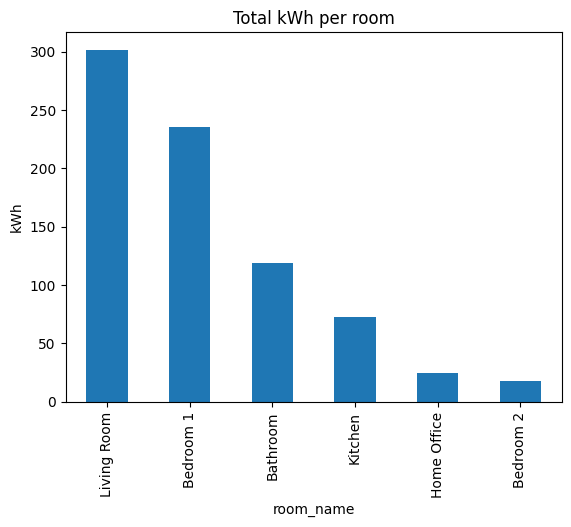

In [15]:
import matplotlib.pyplot as plt
room_summary.plot.bar(x="room_name", y="total_kwh", legend=False, title="Total kWh per room")
plt.ylabel("kWh"); plt.show()

In [16]:
device_summary.to_csv("device_summary.csv", index=False)
room_summary.to_csv("room_summary.csv", index=False)
files.download("energy_logs_clean.csv")
files.download("device_summary.csv")
files.download("room_summary.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>